## Simulação de um gás de Argônio sujeito a um potencial modificado utilizando as ferramentas da Dinâmica Molecular

Esta simulação possui os seguintes objetivos:
- Implementar um potencial de Lennard-Jones em uma simulação de dinâmica molecular clássica (newtoniana) para simular o argônio gasoso, utilizando as seguintes técnicas\ferramentas:
  - Verlet-velocidade (algoritmo de integração das equações do movimento)
  - Condições de contorno periódicas (caixa replicada infinitamente em todas as direções espaciais)
  - Termostato de Langevin
- Realizar a substituição do potencial de Lennard-Jones pelo potencial q-deformado (Alves, 2024)
 - Verificar a validade do potencial q-deformado, mediante comparação das grandezas termodinâmicas (Energia, Pressão, Calor Específico) e da análise da função de correlação g(r)



## Introdução teórica
 A dinâmica molecular (MD, do inglês *Molecular Dynamics*) é um método de simulação computacional que estuda o movimento físico dos átomos e moléculas das quais se conhece o potencial de interação entre estas partículas e as equações que regem o seu movimento (Martínez, 2007). Por tratar-se de um método que lida com grandes quantidades de partículas, a dinâmica molecular, em sua essência, busca resolver numericamente o problema de N-corpos oriundo da mecânica clássica. Em suas formas mais comuns, o movimento das partículas é estudado mediante a resolução numérica das equações do movimento de Newton, enquanto as forças entre as partículas e suas energias potenciais são calculadas por meio de ***potenciais interatômicos***.
 Problemas envolvendo sistemas complexos (com vasto número de partículas) não são resolvidos analiticamente. As simulações de *MD* vêm, portanto, para contornar tal problemática, por meio do uso de métodos numéricos para solucionar tais problemas.
 De acordo com Allen e Tildesley (2007), estas devem ser as características presentes em uma boa simulação de dinâmica molecular:
  1. Deve ser rápida, e deve requerer pouca memória;
  2. Deve permitir o uso de um longo passo de tempo $\delta t$;
  3. Deve replicar a trajetória clássica, mais proximamente possível;
  4. Deve satisfazer as leis de conservação do momentum e da energia, e ser reversível no tempo;
  5. Deve ser simples (em forma) e fácil de programar.
Portanto, a MD deve partir de ferramentas fáceis de se compreender, passando por processos computacionais complexos (envolvendo milhares de cálculos por segundo), até obter resultados que compreendem as grandezas termodinâmicas e os fenômenos de transporte.

# Fundamentos 
## I. Ensemble termodinâmico

 Uma simulação de dinâmica molecular busca, em sua essência, resolver um problema de n-partículas. Uma forma tradicional de tratar tal problema, seguindo os métodos da Mecânica Estatística, consiste na adoção de um **Ensemble**. Por definição, um ensemble é um conjunto de todos os estados microscópicos acessíveis a um sistema, que constituem um mesmo estado macroscópico. A grosso modo, o ensemble é uma coleção de um número muito grande de cópias virtuais de um sistema, cada qual representando um microestado específico (posições e momentos de cada átomo). No entanto, todas as cópias estãos sujeitas às mesmas condições globais (por exemplo: número de partículas, volume e temperatura).
 Para a simulação realizada aqui, o ensemble considerado será o Canônico, também conhecido como NVT em virtude de sua configuração: cada letra representa a grandeza macroscópica a ser considerada como constante. Neste caso:
  - N (número de partículas) = constante;
  - V (volume do sistema) = constante;
  - T (temperatura do sistema) = constante.


## II. Potencial de interação interatômico

As funções potencial são de suma importância para o uso dos métodos da MD; por meio delas, é possível estabelecer um potencial de interação entre duas partículas, o qual depende apenas do módulo da distância entre elas. Dessa equação potencial, é possível utilizar uma relação básica da Mecânica Clássica para obter uma expressão para a força:
 $$\vec{F} = - \nabla U$$
Ou seja, a força é igual ao negativo do gradiente da função potencial.

O potencial inter-atômico mais conhecido é o de Lennard-Jones, ou potencial 12-6:
$$U_{LJ} = 4\epsilon \left[\left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^6\right]$$
Nesta equação, $\sigma$ representa a distância entre as moléculas para a qual o potencial é nulo, e $- \epsilon$ é o valor para o qual o potencial $U_{LJ}$ é mínimo.

<figure style="text-align: center; margin: auto;">
  <img src="LJ_grafico.png" width="300" alt="Raio de corte" style="display: block; margin: 0 auto;">
  <figcaption style="font-size: 14px; color: #666; font-style: italic; margin-top: 8px;">
    Figura 2: Gráfico da interação entre duas partículas sujeitas ao potencial de Lennard-Jones (Shekaari; Jafari, 2021).
  </figcaption>
</figure>

$$$$

Uma generalização desta forma de potencial, proposta por Alves; et al. (2024) e aplicada a sólidos a altas pressões, apresenta a seguinte forma:

$$\Phi (\nu) = \frac{V_0 B_0}{(q-1)^2}\left[ \frac{1}{2} \nu^{-2(q-1)} - \nu^{-(q-1)} \right]$$

Na qual:
 - $\nu$: volume relativo ($V/V_0$)
 - $V_0$: volume inicial do sólido não deformado (quando $P=0$)
 - $B_0$: módulo de incompressibilidade (quando $P=0$)
 - $q$: parâmetro derivado da teoria das funções q-deformadas.

É possível mostrar que este potencial (o qual será implementado na simulação) é equivalente ao 12-6 (para $q-1 = 2$). Da equação $(70)$ de (ref.: qeos), $\nu ^{-(1/3)}=(\frac{a}{r})$. Fazendo a substituição de $\nu$ e utilizando $q-1$ = 2:

$$\Phi (r) = \frac{V_0 B_0}{4}\left[ \frac{1}{2} \left(\frac{a}{r}\right)^{12} - \left(\frac{a}{r}\right)^{6} \right] = C \left[ \frac{1}{2} \left(\frac{a}{r}\right)^{12} - \left(\frac{a}{r}\right)^{6} \right] $$

Na distância de equilíbrio, $r = a$ e $\Phi (r) = -\epsilon$. Portanto,

$$\Phi(r) = C \left[ \frac{1}{2} \left(\frac{a}{a}\right)^{12} - \left( \frac{a}{a} \right)^6 \right] = C \left( \frac{1}{2} - 1\right) = -\frac{C}{2} = -\epsilon \implies C = 2 \epsilon$$
$$\therefore \Phi(r) = 2 \epsilon \left[ \frac{1}{2} \left(\frac{a}{r}\right)^{12} - \left(\frac{a}{r}\right)^{6} \right]$$

A uma distância $\sigma$, o potencial é nulo. Logo,

$$ 2 \epsilon \left[ \frac{1}{2} \left(\frac{a}{\sigma}\right)^{12} - \left(\frac{a}{\sigma}\right)^{6} \right] = 0 \implies \frac{1}{2} \left(\frac{a}{\sigma}\right)^{12} - \left(\frac{a}{\sigma}\right)^{6}  = 0 \implies \left( \frac{a}{\sigma} \right)^6 =  \frac{1}{2} \left(\frac{a}{\sigma}\right)^{12} \implies a^6 = 2 \sigma^6 \ , \ a^{12} = 4 \sigma ^{12}$$

$$ \therefore \Phi (r) = 2 \epsilon \left( \frac{1}{2} \frac{4 \sigma ^{12}}{r^{12}} - \frac{2 \sigma ^6}{r^6}\right) = 4 \epsilon \left[ \left(\frac{\sigma}{r}\right)^{12} - \left(\frac{\sigma}{r}\right)^{6} \right] $$

Mostrando que o potencial proposto é uma generalização do potencial de Lennard-Jones. Como foi identificado $C = \frac{V_0 B_0}{4} = 2 \epsilon$, e portanto, $4 \epsilon = 2 C$, e $q-1 = 2$, é possível escrever o potencial generalizado na seguinte forma:

$$\Phi (r) = 4 \epsilon \left[ \left( \frac{\sigma}{r} \right)^{2[{3(q-1)}]} - \left( \frac{\sigma}{r} \right)^{3(q-1)} \right] = 4 \epsilon \left[ \left( \frac{\sigma}{r} \right)^{2m} - \left( \frac{\sigma}{r} \right)^{m} \right] \ , \ m = 3(q-1)$$

Este será o potencial utilizado na simulação. A expressão para a força, portanto, será:

$$F= - \nabla \Phi (r) = 4 \epsilon \left(-2m \frac{\sigma ^{2m}}{r^{2m+1}}+ m \frac{\sigma ^m}{r^{m+1}}\right)$$


## Raio de corte
Do ponto de vista computacional, torna-se custoso realizar cálculos de interações de átomos a distâncias elevadas (em comparação com o tamanho do átomo). Por conta disso, é padrão admitir, em simulações de Dinâmica Molecular, um raio de corte. Dada uma partícula fixa, quaisquer outras partículas que estejam fora do raio de corte desta não sofrerão interação da mesma.
A justificativa para o uso de um raio de corte é a seguinte:

<figure style="text-align: center; margin: auto;">
  <img src="r_ct.png" width="300" alt="Raio de corte" style="display: block; margin: 0 auto;">
  <figcaption style="font-size: 14px; color: #666; font-style: italic; margin-top: 8px;">
    Figura 2: Ilustração de uma partícula com um raio de corte (Shekaari; Jafari, 2021).
  </figcaption>
</figure>

$$$$

Seja $\rho$ a densidade de partículas da figura 2. É possível escrever, como função de $\rho$,

$$\Delta U dn = \frac{\rho \ 4 \pi r^2 dr}{r^{\alpha}} \propto r^{2 - \alpha}$$

- Se $\alpha < 2$, a interação é proporcional a uma potência positiva de $r$, e $lim_{\ r \rightarrow \infty} \ \Delta U = \infty$
 - Essa interação é identificada como sendo de *longo alcance*, pois ocorre para partículas a distâncias muito grandes 
- Se $\alpha > 2$, a interação é proporcional a uma potência negativa de $r$, e $lim_{\ r \rightarrow \infty} \ \Delta U = 0$
 - Essa interação é de *curto alcance*: para partículas muito distantes, o potencial tende a zero.
A interação do potencial modificado cumpre a segunda possibilidade ($\alpha > 2$) para $q-1 = 2$. Logo, pode ser caracterizado como uma interação de curto alcance.

## Unidades reduzidas
Não é proveitoso, do ponto de vista computacional, utilizar unidades reais nos cálculos; o acúmulo de arredondamentos na própria máquina pode induzir erros muito grandes e fazer com que a simulação falhe. De modo que, em simulações de Dinâmica Molecular, são adotadas *Unidades reduzidas*. Por definição, $m* = 1, \sigma = 1, \epsilon = 1$. A reconstituição das unidades depende do material a ser simulado. Para o argônio, por exemplo: 
 - $m = m* \ m_A $ ($m$: massa real, $m$: massa do argônio)
 - $E = E* \ \epsilon _A$ ($E$: energia real, $\epsilon$: valor numérico do poço de profundidade no potencial de Lennard-Jones para o argônio)
 - $r = r* \ \sigma _A$ ($r$: distância real,$\sigma$: valor numérico do tamanho do átomo no potencial de Lennard-Jones para o argônio)

# Preliminares da simulação
## Integração das equações do movimento

## Termostato
Como a simulação está rodando no ensemble canônico (NVT), é necessário um meio de manter a temperatura do sistema constante. Isso é feito por meio de um Termostato. 
Do teorema da equipartição de energia, a temperatura pode ser escrita como:

$$T = \frac{1}{3 N k_B}\left< \sum_{i=1}^{N} m_i {v_i}^2 \right>$$

Isso implica numa dependência da temperatura em relação à velocidade. Se essa temperatura puder ser reescalada (i.e., sua velocidade for multiplicada por uma constante para manter a temperatura original), o sistema pode ter sua temperatura mantida, ou oscilando, em torno de uma temperatura fixa, identificada ao início da simulação. O Termostato vem para cumprir esta função: a de manter o sistema com uma temperatura "fixa". Existem vários tipos de termostatos na literatura: Berendsen, Nosé-Hoover, Andersen, etc. Nessa simulação, será dada ênfase ao termostato de Langevin.

### Termostato de Langevin

O termostato de Langevin é desenvolvido a partir da seguinte equação do movimento:

$$ m \frac{dv}{dt} = F(r) - \gamma v + R(t)$$

- $F(r)$: força da interação potenical (nesse caso, a do potencial q-deformado)
- $- \gamma v$: termo de atrito
- $R(t)$: ruído estatístico

O atrito dissipa energia do sistema, enquanto o ruído aquece o sistema indefinidamente. Quando ambos estão em equilíbrio (relacionados pelo teorema de flutuação-disspiação da energia) é que o sistema converge para a temperatura determinada no início da simulação.

A solução exata da equação do movimento é:

$$ v(t+dt)=e^{−γdt}v(t)+\sqrt{T_0(1−e−2γdt)} \ ξ$$

## Condições de contorno periódicas

## Cálculo da pressão

In [47]:
import time
from math import sqrt, copysign
import numpy as np
from numba import njit, prange
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, MaxNLocator

%matplotlib inline

class Config:
    SEED = 42 # seed do gerador de números aleatórios. Garante que, para cada vez que o código for rodado, as posições e as velocidades 
              # iniciais sejam as mesmas
    DIM = 3 # número de dimensões do sistema
    N = 864 # quantidade de átomos
    rho = 0.1 # densidade reduzida. A densidade real pode ser calculada por
              # : rho_real = (rho * massa molar do argônio)/(número de avogadro * sigma^3)
    vol = N / rho # volume da caixa de simulação
    aresta = vol**(1/3) # aresta da caixa de simulação
    NS = 300000 # número de passos da simulação
    dt = 0.001 # intervalo de tempo nos quais os passos da simulação irão atuar
    ign = 10000 # passos a serem ignorados no início da simulação. Serve para calcular as médias termodinâmicas do sistema
    T_0 = 2.5 # temperatura em unidades reduzidas. A temperatura real pode ser calculada por
              # T = (T_0 * epsilon) / constante de Boltzmann
    tau = 0.01 # 
    epsilon = 1.0
    sigma = 1.0
    r_ct = 2.5 * sigma # raio de corte
    sr_ct = sigma / r_ct
    q = 3.0 # parâmetro adimensional do potencial q-deformado
    m = 3.0 * (q - 1.0)
    sr_ct_m = sr_ct**m
    sr_ct_2m = sr_ct_m**2
    u_ct = 4.0 * epsilon * (sr_ct_2m - sr_ct_m)
    u_tail = 8.0 * np.pi * rho * epsilon * (sigma**3) * ((1.0 / (2.0 * m - 3.0)) * sr_ct**(2.0 * m - 3.0) - (1.0 / (m - 3.0)) * sr_ct**(m - 3.0))
    p_tail = (8.0 / 3.0) * np.pi * (rho**2) * epsilon * m * (sigma**3) * ((2.0 / (2.0 * m - 3.0)) * sr_ct**(2.0 * m - 3.0) - (1.0 / (m - 3.0)) * sr_ct**(m - 3.0))
    # u_tail e p_tail são as correções de cauda da energia potencial e da pressão, respectivamente. Para mais informações,
    # consultar Allen e Tildesley (2007)
config = Config()


In [48]:
@njit(fastmath=True, parallel=True)
def forcas(pos, N, dim, aresta, r_ct, epsilon, sigma, u_ct, m):

# Inicia uma matriz que conterá os valores da aceleração de cada partícula em cada um dos eixos coordenados, um vetor contendo 
# o potencial sofrido por cada partícula e outro vetor que acumulará o virial de cada partícula
    
    acc = np.zeros((dim, N))
    pot = np.zeros(N)
    vrl_por_particula = np.zeros(N)

    
    sigma2 = sigma * sigma
    r_ct2 = r_ct * r_ct
    m_metade = m / 2.0

    for i in prange(N): # loop sobre todas as partículas do sistema
        for j in range(N): # loop que calcula a partícula fixada "i" com as outras partículas "j"
            if i != j: # garante que i seja diferente de j (ao invés de usar range(i+1) no loop; economiza processamento)
                r2_ij = 0.0 # variável que guardará a distância entre as partículas
                R_ij = np.zeros(dim) # vetor que aponta de uma partícula para a outra 

                for k in range(dim):
                    R_ij[k] = pos[k, i] - pos[k, j] # Encontra a distância em coordenadas fracionárias
                    if abs(R_ij[k]) > 0.5:
                        R_ij[k] -= copysign(1.0, R_ij[k]) # Aplicação da convenção da imagem mínima: se a distância passar de 
                                                          # metade da caixa, a partícula "j" interage com a cópia de "i" na caixa
                                                          # imagem vizinha
                    r_k = aresta * R_ij[k] # transforma distância fracionária em distância real
                    r2_ij += r_k * r_k # soma as distâncias dos quadrados nos eixos. Como k varia de 1 a 3, teremos
                                       # r_1² + r_2² + r_3² + ...

                if r2_ij < r_ct2: # verifica se a partícula está no raio de corte. A seguir, calcula-se 
                    sr2 = sigma2 / r2_ij 
                    
                    srm = sr2 ** m_metade
                    sr2m = srm * srm

                    u = 4.0 * epsilon * (sr2m - srm) - u_ct # cálculo do potencial, subtraindo o raio de corte
                    pot[i] += 0.5 * u # soma metade da energia de uma partícula (a outra partícula interagente somará a outra metade),
                                      # para evitar contagem dupla

                    du = (4.0 * epsilon * m / r2_ij) * (2.0 * sr2m - srm) # módulo da força
                    vrl_por_particula[i] -= 0.5 * du * r2_ij # 

                    for k in range(dim):
                        acc[k, i] += du * R_ij[k] # Força aplicada nos três eixos vetoriais (m* = 1, portanto força = aceleração)

    vrl = vrl_por_particula.sum() # soma todos os termos do virial da partícula
    return acc, pot, -vrl / dim # calcula o virial dividido por três

In [49]:
def conversao(T_red, P_red, rho_red, cv_red, E_red):
    eps_kb = 119.8
    sigma = 3.405
    M = 39.95
    R = 8.31446

    T_real = T_red * eps_kb
    rho_real = rho_red * (M / (0.602214 * sigma**3))
    P_real = P_red * ((eps_kb * 138.0649) / (sigma**3))

    cv_real = (cv_red + 1.5) * R
    U_real = E_red * eps_kb * R / 1000.0

    return T_real, P_real, rho_real, cv_real, U_real


def block_average(dados, n_blocos=20):
    dados = np.asarray(dados)
    n = len(dados)
    if n < 2:
        return (dados[0] if n == 1 else 0.0), 0.0

    n_blocos = max(1, min(n_blocos, n))
    blocos = np.array_split(dados, n_blocos)
    medias_bloco = np.array([b.mean() for b in blocos if len(b) > 0])
    media_global = dados.mean()
    erro = medias_bloco.std(ddof=1) / np.sqrt(len(medias_bloco)) if len(medias_bloco) > 1 else 0.0
    return media_global, erro


def block_cv(pot_series, N, T0, n_blocos=20):
    pot_series = np.asarray(pot_series)
    n = len(pot_series)
    if n < 4:
        return 0.0, 0.0

    n_blocos = max(2, min(n_blocos, n // 2))
    blocos = np.array_split(pot_series, n_blocos)
    cvs = np.array([
        (b.var() * (N**2)) / (N * (T0**2))
        for b in blocos if len(b) > 1
    ])
    if len(cvs) > 1:
        return cvs.mean(), cvs.std(ddof=1) / np.sqrt(len(cvs))
    return (cvs[0] if len(cvs) == 1 else 0.0), 0.0


def _rdf_histograma_frame(pos, aresta, bins, N):
    delta = pos[:, None, :] - pos[None, :, :]          
    delta -= aresta * np.round(delta / aresta)          
    r = np.sqrt(np.sum(delta * delta, axis=-1))         

    iu = np.triu_indices(N, k=1)
    r_pairs = r[iu]
    rmax = bins[-1]
    r_pairs = r_pairs[r_pairs < rmax]

    hist, _ = np.histogram(r_pairs, bins=bins)
    return hist * 2  


def calc_analise():
    resultado = {
        'C_v': 0.0, 'C_v_err': 0.0,
        'T_med': 0.0, 'T_err': 0.0,
        'P_med': 0.0, 'P_err': 0.0,
        'K_med': 0.0, 'K_err': 0.0,
        'U_med': 0.0, 'U_err': 0.0,
        'E_med': 0.0, 'E_err': 0.0,
        'dados_reais': conversao(0.0, 0.0, config.rho, 0.0, 0.0),
        'r': np.array([0]), 'gr': np.array([0]),
        'tpz': None, 'kpe': None,
        'u_tail': config.u_tail, 'p_tail': config.p_tail
    }

    try:
        tpz = np.loadtxt('tpz.out')
        kpe = np.loadtxt('kpe.out')
        resultado['tpz'], resultado['kpe'] = tpz, kpe

        ign = config.ign
        T_series = tpz[ign:, 1]
        P_series_bruto = tpz[ign:, 2]
        K_series = kpe[ign:, 1]
        U_series_bruto = kpe[ign:, 2]
        E_series_bruto = kpe[ign:, 3]

        T_med, T_err = block_average(T_series)
        P_med_bruto, P_err = block_average(P_series_bruto)
        K_med, K_err = block_average(K_series)
        U_med_bruto, U_err = block_average(U_series_bruto)
        E_med_bruto, E_err = block_average(E_series_bruto)

        P_med = P_med_bruto + config.p_tail
        U_med = U_med_bruto + config.u_tail
        E_med = E_med_bruto + config.u_tail

        C_v, C_v_err = block_cv(U_series_bruto, config.N, config.T_0)

        resultado.update({
            'C_v': C_v, 'C_v_err': C_v_err,
            'T_med': T_med, 'T_err': T_err,
            'P_med': P_med, 'P_err': P_err,
            'K_med': K_med, 'K_err': K_err,
            'U_med': U_med, 'U_err': U_err,
            'E_med': E_med, 'E_err': E_err,
        })
        resultado['dados_reais'] = conversao(T_med, P_med, config.rho, C_v, E_med)

    except OSError as e:
        print(f"[calc_analise] Aviso: não foi possivel ler tpz.out/kpe.out ({e}). "
              f"Resultados serão reportados como zero.")
        return resultado
    except (IndexError, ValueError) as e:
        print(f"[calc_analise] Aviso: tpz.out/kpe.out com formato inesperado ({e}). "
              f"Verifique se a simulação rodou ate o fim.")
        return resultado

    # Processamento das posições (g(r)) 
    try:
        with open('pos.xyz', 'r') as f:
            linhas_pos = f.readlines()
            
        passos = []
        idx = 0
        while idx < len(linhas_pos):
            n_atoms = int(linhas_pos[idx])
            idx += 2
            coords = []
            for _ in range(n_atoms):
                partes = linhas_pos[idx].split()
                c = partes[1:] if partes[0].isalpha() else partes
                coords.append([float(c[0]), float(c[1]), float(c[2])])
                idx += 1
            passos.append(np.array(coords))

        fotos_ignoradas = config.ign // 100
        trajetoria = np.array(passos)[fotos_ignoradas:]
        n_frames = len(trajetoria)

        if n_frames > 1:
            dr = 0.1
            rmax = config.aresta / 2.0
            n_bins = int(round(rmax / dr))
            bins = np.linspace(0, n_bins * dr, n_bins + 1)
            hist_total = np.zeros(n_bins)
            
            for t in range(n_frames):
                hist_total += _rdf_histograma_frame(trajetoria[t], config.aresta, bins, config.N)

            r_centros = bins[:-1] + dr / 2.0
            g_r = np.zeros_like(hist_total)
            for i, r in enumerate(r_centros):
                vol_casca = 4.0 * np.pi * r**2 * dr
                g_r[i] = (hist_total[i] / n_frames) / (config.N * config.rho * vol_casca)

            resultado['r'] = r_centros[:-1]
            resultado['gr'] = g_r[:-1]
            
    except OSError as e:
        print(f"[calc_analise] Aviso: não foi possível ler pos.xyz ({e}). g(r) não será calculado.")

    return resultado

In [50]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['xtick.top'] = True
plt.rcParams['ytick.right'] = True
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['lines.linewidth'] = 1.8

def graficos():
    resultado = calc_analise()
    T_real, P_real, rho_real, cv_real, U_real = resultado['dados_reais']

    P_nist_mpa = 10.023
    U_nist = 3.1270
    Cv_nist = 13.146

    P_real_mpa = P_real / 10.0

    erro_P = abs(P_real_mpa - P_nist_mpa) / P_nist_mpa * 100.0
    erro_U = abs(U_real - U_nist) / U_nist * 100.0
    erro_Cv = abs(cv_real - Cv_nist) / Cv_nist * 100.0

    print(f"\n{'='*65}")
    print(f"      Comparação com os dados do NIST")
    print(f"{'='*65}")
    print(f" Propriedade         | Simulação      | NIST           | Erro (%)")
    print(f"-----------------------------------------------------------------")
    print(f" Pressao (MPa)       | {P_real_mpa:14.4f} | {P_nist_mpa:14.4f} | {erro_P:7.2f}%")
    print(f" Energia (kJ/mol)    | {U_real:14.4f} | {U_nist:14.4f} | {erro_U:7.2f}%")
    print(f" Calor Espec. (C_v)  | {cv_real:14.4f} | {Cv_nist:14.4f} | {erro_Cv:7.2f}%")
    print(f"{'='*65}")
    print(f" Correção de cauda aplicada: u_tail = {resultado['u_tail']:.4f}  "
          f"p_tail = {resultado['p_tail']:.4f}  (unid. reduzidas)")
    print(f"{'-'*65}")
    print(f" Médias em unidades reduzidas (com incerteza via block averaging):")
    print(f"   T*  = {resultado['T_med']:.4f} +/- {resultado['T_err']:.4f}")
    print(f"   P*  = {resultado['P_med']:.4f} +/- {resultado['P_err']:.4f}  (com correção de cauda)")
    print(f"   U*  = {resultado['U_med']:.4f} +/- {resultado['U_err']:.4f}  (com correção de cauda)")
    print(f"   E*  = {resultado['E_med']:.4f} +/- {resultado['E_err']:.4f}  (com correção de cauda)")
    print(f"   C_v = {resultado['C_v']:.4f} +/- {resultado['C_v_err']:.4f}")
    print(f"{'='*65}\n")

    tpz, kpe = resultado['tpz'], resultado['kpe']
    r, gr = resultado['r'], resultado['gr']

    if tpz is not None and kpe is not None:
        
        fig2, ax2 = plt.subplots(figsize=(6, 4.5))
        ax2.plot(r, gr, color='black')
        ax2.axhline(1.0, color='gray', ls='--', lw=1.2)
        ax2.set_xlabel(r'$r/\sigma$')
        ax2.set_ylabel(r'$g(r)$')
        ax2.set_xlim(0, max(r))
        ax2.set_ylim(0, max(gr) * 1.1)
        ax2.xaxis.set_major_locator(MaxNLocator(prune='lower'))
        ax2.xaxis.set_minor_locator(AutoMinorLocator())
        ax2.yaxis.set_minor_locator(AutoMinorLocator())
        plt.tight_layout()
        plt.savefig('RDF_Relatorio.pdf')

        plt.show()

Inicio da simulacao.
10.0%
20.0%
30.0%
40.0%
50.0%
60.0%
70.0%
80.0%
90.0%
100.0%
Tempo de simulação: 604.46 s

      Comparação com os dados do NIST
 Propriedade         | Simulação      | NIST           | Erro (%)
-----------------------------------------------------------------
 Pressao (MPa)       |         9.7593 |        10.0230 |    2.63%
 Energia (kJ/mol)    |         3.1437 |         3.1270 |    0.53%
 Calor Espec. (C_v)  |        12.8599 |        13.1460 |    2.18%
 Correção de cauda aplicada: u_tail = -0.0535  p_tail = -0.0107  (unid. reduzidas)
-----------------------------------------------------------------
 Médias em unidades reduzidas (com incerteza via block averaging):
   T*  = 2.4977 +/- 0.0005
   P*  = 0.2329 +/- 0.0005  (com correção de cauda)
   U*  = -0.5906 +/- 0.0025  (com correção de cauda)
   E*  = 3.1560 +/- 0.0027  (com correção de cauda)
   C_v = 0.0467 +/- 0.0027



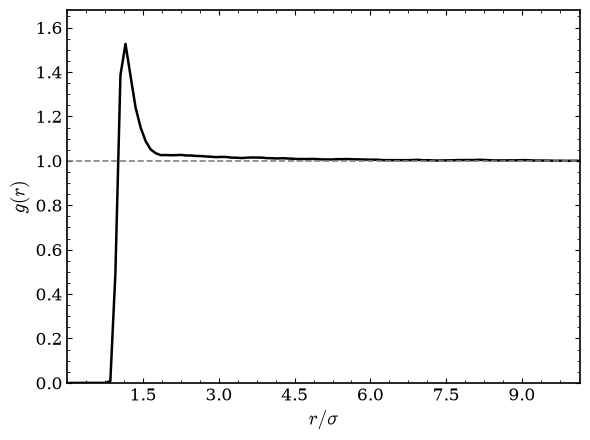

In [51]:
def estatisticas(vel, aresta, dim):             
    v2_total = np.sum((vel * aresta)**2)        # converte a velocidade em unidades reais e eleva ao quadrado
    k_avg = 0.5 * v2_total / config.N           # média macroscópica da energia cinética
    temp_i = 2.0 * k_avg / dim                  # pelo Teorema de Equipartições de Energia, transforma os Joules numa escala Celsius/Kelvin baseada nas 'Dimensões (3)'
    return k_avg, temp_i                        # retorna a energia em movimento e a temperatura viva do balão

def main():                                    
    np.random.seed(config.SEED)                 

    pos = np.zeros((config.DIM, config.N))      # matriz das coordenadas de cada partícula
    n_lado = int(np.ceil(config.N**(1/3)))      # cria a estrutura cúbica para posicionar os átomos
    espacamento = 1.0 / n_lado                  # estabelece a distância entre os átomos da caixa na posição inicial

    idx = 0                                    
    for ix in range(n_lado):                    # loop de posicionamento das partículas
        for iy in range(n_lado):              
            for iz in range(n_lado):           
                if idx < config.N:              # loop que posiciona os átomos em cada posição, enquanto ainda houver
                    pos[0, idx] = -0.5 + (ix + 0.5) * espacamento # 
                    pos[1, idx] = -0.5 + (iy + 0.5) * espacamento # ======> definição das coordenadas x, y e z de cada átomo
                    pos[2, idx] = -0.5 + (iz + 0.5) * espacamento # 
                    idx += 1                    # Passa a caneta para o próximo átomo da fila

    vel = np.random.uniform(-0.5, 0.5, (config.DIM, config.N)) # Randomiza as velocidades iniciais
    vel -= np.mean(vel, axis=1, keepdims=True)  # Ajusta o Momentum Global Inicial igual a "ZERO" (Subtrai o vetor global. Se não fizer isso, a "Garrafa inteira de gás voará pelo espaço")

    print(f"Inicio da simulacao.")    
    start_time = time.time()

    tpz_buf = np.zeros((config.NS, 4)) # array de tamanho NS para armazenar temperatura e pressão
    kpe_buf = np.zeros((config.NS, 4)) # array semelhante, para guardar as energias (potencial, cinética)


# Aplicação do termostato de Langevin
    c1 = np.exp(-config.dt / config.tau)     
    c2 = np.sqrt((1.0 - c1**2) * config.T_0) / config.aresta 

    with open('pos.xyz', 'w') as f_xyz, open('vel.out', 'w') as f_vel: 

        pos[pos > 0.5] -= 1.0  # aplicação das condições de contorno periódicas no início da simulação
        pos[pos < -0.5] += 1.0

        # Aciona a função que calcula as forças
        acc, pot, vrl = forcas(pos, config.N, config.DIM, config.aresta,
                               config.r_ct, config.epsilon, config.sigma, config.u_ct, config.m)

        for step in range(1, config.NS + 1):   
            
            # desloca e atualiza as posições geométricas dos átomos prevendo os próximos instantes
            pos += config.dt * vel + 0.5 * acc * config.dt**2

            # aplica o banho de calor estocástico 
            ruido = np.random.normal(0.0, 1.0, (config.DIM, config.N))
            ruido -= np.mean(ruido, axis=1, keepdims=True) # Remove média de deriva das vibrações (Para o gás não voar de lado magicamente)
            
            # ajusta temporariamente e atenua a inércia Newtoniana (c1 * vel) enquanto soma o chute de ruído térmico (c2 * Ruido)
            vel_termo = c1 * vel + c2 * ruido
            
            # calcula a nova direção cinética parcial após o choque
            vel_meia = vel_termo + 0.5 * config.dt * acc

            # aplica novamente as condições de contorno periódicas
            pos[pos > 0.5] -= 1.0               
            pos[pos < -0.5] += 1.0            

            # aciona novamente a função de cálculo das forças, no instante t + dt
            acc, pot, vrl = forcas(pos, config.N, config.DIM, config.aresta,
                                   config.r_ct, config.epsilon, config.sigma, config.u_ct, config.m)
            
            # velocidade em t + dt
            vel = vel_meia + 0.5 * config.dt * acc

            # cálculos estatísticos e termodinâmicos 
            k_avg, T_i = estatisticas(vel, config.aresta, config.DIM) # calcula a temperatura e a energia cinética do instante atual
            p_avg = np.mean(pot)                # calcula a média de atração
            pres = config.rho * T_i + vrl / config.vol # calcula o virial
            z_comp = pres / (config.rho * T_i) if T_i > 0 else 1.0 

            tpz_buf[step - 1] = (step * config.dt, T_i, pres, z_comp)           # salvam os dados na memória 
            kpe_buf[step - 1] = (step * config.dt, k_avg, p_avg, k_avg + p_avg) # 

            if step % 100 == 0:                
                f_xyz.write(f"{config.N}\nPasso {step}\n") # 
                f_vel.write(f"{config.N}\nPasso {step}\n") # 

                np.savetxt(f_xyz, (pos * config.aresta).T, fmt='Ar %.4f %.4f %.4f') # Imprime as posições escaladas
                np.savetxt(f_vel, vel.T, fmt='Ar %.6e %.6e %.6e') # Imprime formato numérico com notação Exponencial para ser lido depois por VMD

            if step % (config.NS // 10) == 0:   # Andamento da simulação
                print(f"{(step / config.NS) * 100:.1f}%") 

    np.savetxt('tpz.out', tpz_buf, fmt='%.6e')  # descarrega os arquivos
    np.savetxt('kpe.out', kpe_buf, fmt='%.6e')  # 

    print(f"Tempo de simulação: {time.time() - start_time:.2f} s") 
    graficos()
    
main()                                       

## Referências:

